# Adversarial checks

These are explicitly procedural counterexamples and Monte Carlo simulations, reported separately from the two-game corpus.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
ROOT = Path.cwd()
if not (ROOT / 'data').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.metrics import *


In [2]:
chains=pd.read_csv(ROOT/'results/path_saturation.csv')
assert ((chains.transition_distance-4/(chains.length+2)).abs()<1e-12).all()
chains

,family,length,transition_distance,path_distance,endpoint_distance
0,chain,4,0.666667,1.0,0.0
1,chain,8,0.400000,1.0,0.0
2,chain,16,0.222222,1.0,0.0
3,chain,32,0.117647,1.0,0.0
4,chain,64,0.060606,1.0,0.0
5,chain,128,0.030769,1.0,0.0


In [3]:
sampling=pd.read_csv(ROOT/'results/coverage_simulation.csv')
sampling[sampling.rare_probability==1/64]

,rare_probability,rollouts,replicates,rare_miss_rate,exact_rare_miss,false_directional_loss_rate,false_support_difference_rate
8,0.015625,16,10000,0.7776,7.772652e-01,0.1757,0.3517
9,0.015625,64,10000,0.3678,3.649865e-01,0.2350,0.4720
10,0.015625,256,10000,0.0188,1.774628e-02,0.0187,0.0369
11,0.015625,1024,10000,0.0000,9.918118e-08,0.0000,0.0000


In [4]:
noise=pd.read_csv(ROOT/'results/label_noise.csv.gz')
noise.groupby(['game','rate']).false_distance.mean()

game           rate
emoji          0.00    0.000000
               0.10    0.140416
               0.25    0.332935
               0.50    0.605127
the_intercept  0.00    0.000000
               0.10    0.141387
               0.25    0.332566
               0.50    0.608709
Name: false_distance, dtype: float64

In [5]:
pd.read_csv(ROOT/'results/ablation_summary.csv').pivot_table(index=['game','operation'],columns='representation',values='detected')

representation           full     state  terminal      text
game          operation                                    
emoji         collapse    1.0  0.979279       0.0  0.998465
              drop        1.0  1.000000       1.0  1.000000
              permute     1.0  0.967778       0.0  0.996667
the_intercept collapse    1.0  0.689114       0.0  1.000000
              drop        1.0  1.000000       1.0  1.000000
              permute     1.0  0.664234       0.0  1.000000

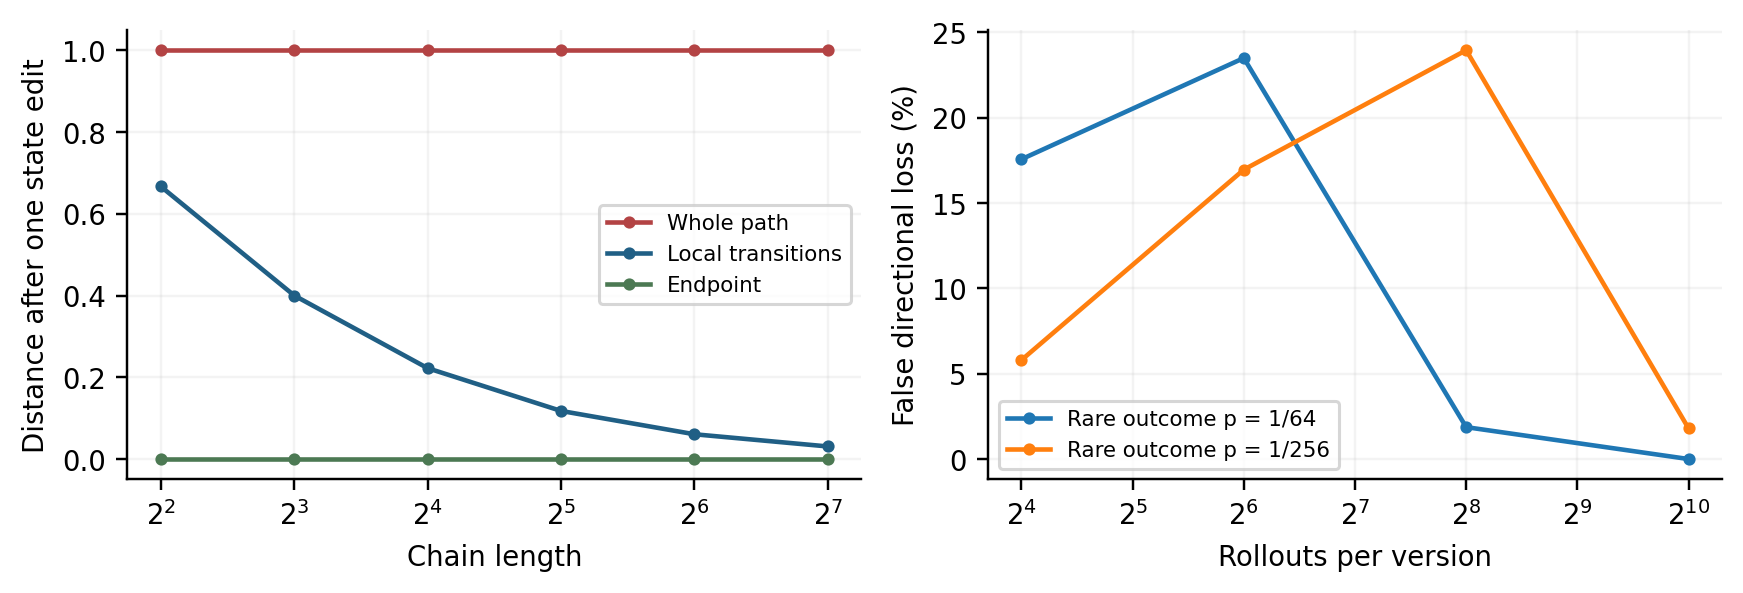

In [6]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'figures/robustness.png')))

### Limits
An unchanged game can show apparent loss under incomplete sampling. Frozen labels can conceal semantic errors. A one-step signature cannot establish long-horizon possibility, perceived agency, originality, or an AI treatment effect.